# Data Visualizations, Statistical Measures, Correlations, Autocorrelations, Probability Distributions

## Explore the environment

In [4]:
# !pip freeze
!python3 --version

Python 3.12.13


## Packages

In [5]:
# Stock data
import yfinance as yf

# Data storage, manipulation and math
import pandas as pd
import numpy as np
from scipy.stats import norm

# Plotting
import matplotlib.pyplot as plt
import seaborn as sns
from pandas.plotting import lag_plot


## Stock Data

In [6]:
ticker = 'CSCO'
stock = yf.download(
    tickers=ticker,
    period = '1d',
    interval='1m'
  )
stock.head()

/tmp/ipykernel_30757/467462448.py:2: FutureWarning: YF.download() has changed argument auto_adjust default to True
  stock = yf.download(
[*********************100%***********************]  1 of 1 completed


Price,Close,High,Low,Open,Volume
Ticker,CSCO,CSCO,CSCO,CSCO,CSCO
Datetime,,,,,
2026-06-23 13:30:00+00:00,118.136002,118.989998,118.129997,118.522301,555583
2026-06-23 13:31:00+00:00,118.385002,118.500000,117.718498,118.260002,87001
2026-06-23 13:32:00+00:00,118.290001,118.709999,118.154999,118.385002,32824
2026-06-23 13:33:00+00:00,118.099998,118.370003,117.970001,118.285004,52490
2026-06-23 13:34:00+00:00,118.470001,118.470001,118.074997,118.099998,31505


<Axes: xlabel='Datetime'>

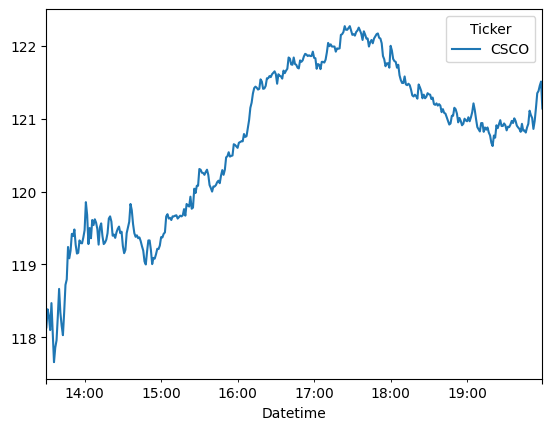

In [7]:
stock['Close'].plot()

## Multiple Stocks

In [8]:
stock_data = yf.download(
    tickers=['SPY', 'MSFT', 'AAPL', 'NVDA', 'CSCO', 'TSLA'],
    start="2024-01-01"
)

stock_data.head()

/tmp/ipykernel_30757/3209255233.py:1: FutureWarning: YF.download() has changed argument auto_adjust default to True
  stock_data = yf.download(
[*********************100%***********************]  6 of 6 completed


Price            Close                                                \
Ticker            AAPL       CSCO        MSFT       NVDA         SPY   
Date                                                                   
2024-01-02  183.562164  47.178463  363.801453  48.082535  458.809174   
2024-01-03  182.187744  47.545570  363.536621  47.484600  455.062256   
2024-01-04  179.873932  47.140812  360.927338  47.912838  453.596436   
2024-01-05  179.152115  47.150223  360.740967  49.009884  454.217712   
2024-01-08  183.483078  47.498508  367.548706  52.160286  460.702118   

Price                         High                                    ...  \
Ticker            TSLA        AAPL       CSCO        MSFT       NVDA  ...   
Date                                                                  ...   
2024-01-02  248.419998  186.330827  47.505380  368.735583  49.207534  ...   
2024-01-03  238.449997  183.799505  47.705595  366.145927  48.098507  ...   
2024-01-04  237.929993  181.040717  47.545572  365.988995  48.413946  ...   
2024-01-05  237.490005  180.714432  47.413788  364.968819  49.459086  ...   
2024-01-08  240.449997  183.522639  47.536162  368.048995  52.182250  ...   

Price             Open                                       Volume            \
Ticker            MSFT       NVDA         SPY        TSLA      AAPL      CSCO   
Date                                                                            
2024-01-02  366.734456  49.156626  458.333532  250.080002  82488700  20242900   
2024-01-03  361.976929  47.400749  456.654216  244.979996  58414500  20303900   
2024-01-04  363.605317  47.682245  454.586556  239.250000  71983600  18134100   
2024-01-05  361.937716  48.376012  453.800282  236.860001  62379700  13989300   
2024-01-08  362.261421  49.424152  454.712783  236.139999  59144500  18070300   

Price                                                  
Ticker          MSFT       NVDA        SPY       TSLA  
Date                                                   
2024-01-02  25258600  411254000  123623700  104654200  
2024-01-03  23083500  320896000  103585900  121082600  
2024-01-04  20901500  306535000   84232200  102629300  
2024-01-05  21004600  415039000   86118900   92488900  
2024-01-08  23134000  642510000   74879100   85166600  

[5 rows x 30 columns]

<Axes: xlabel='Date'>

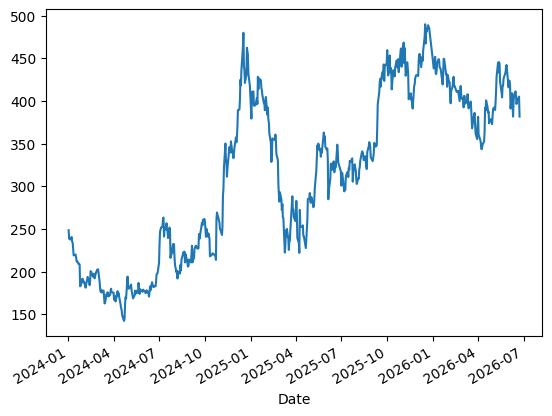

In [9]:
stock_data['Close']['TSLA'].plot()

<Axes: xlabel='Date'>

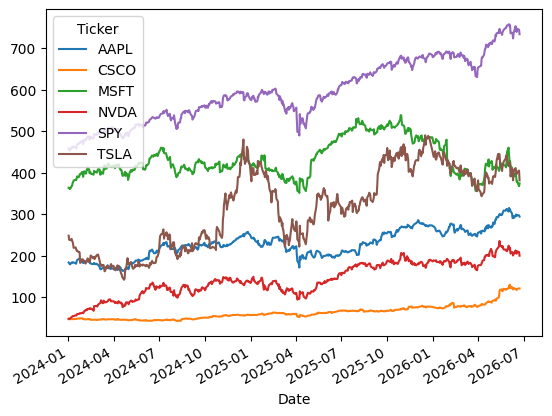

In [10]:
stock_data['Close'].plot()

## Data Descriptions

In [11]:
stock_data.describe()

Price        Close                                                  \
Ticker        AAPL        CSCO        MSFT        NVDA         SPY   
count   620.000000  620.000000  620.000000  620.000000  620.000000   
mean    228.664162   63.140619  432.484382  142.715795  594.749014   
std      34.769314   17.653004   43.374630   41.860578   75.152284   
min     163.361389   42.822033  351.105804   47.484600  453.596436   
25%     202.380581   47.608011  402.741180  114.018978  535.594666   
50%     226.510612   59.732149  418.629990  138.258720  585.729004   
75%     255.529564   71.915903  464.643616  180.724564  662.369370   
max     315.200012  130.000000  538.658569  235.465576  757.618225   

Price                     High                                      ...  \
Ticker        TSLA        AAPL        CSCO        MSFT        NVDA  ...   
count   620.000000  620.000000  620.000000  620.000000  620.000000  ...   
mean    314.810371  230.924633   63.714990  436.271089  145.049807  ...   
std      96.473419   35.094251   17.932115   43.321782   42.287690  ...   
min     142.050003  164.747480   43.226978  360.929166   48.098507  ...   
25%     222.502495  206.141916   47.882864  405.812337  116.321105  ...   
50%     326.259995  228.465644   60.062293  421.964820  140.131041  ...   
75%     404.615005  257.111259   72.420454  469.021860  183.083789  ...   
max     489.880005  317.399994  130.369995  551.048411  236.264633  ...   

Price         Open                                            Volume  \
Ticker        MSFT        NVDA         SPY        TSLA          AAPL   
count   620.000000  620.000000  620.000000  620.000000  6.200000e+02   
mean    432.583148  142.785188  594.629211  314.872274  5.419402e+07   
std      43.570795   42.003276   75.198413   96.683414  2.557754e+07   
min     347.461647   47.400749  453.800282  140.559998  1.791060e+07   
25%     402.746286  113.838463  536.008367  224.367504  4.052902e+07   
50%     418.521227  138.555828  586.687626  326.554993  4.807475e+07   
75%     464.503939  180.964259  662.689484  404.377487  5.945115e+07   
max     550.830123  229.602402  756.201867  489.880005  3.186799e+08   

Price                                                                         
Ticker          CSCO          MSFT          NVDA           SPY          TSLA  
count   6.200000e+02  6.200000e+02  6.200000e+02  6.200000e+02  6.200000e+02  
mean    2.078561e+07  2.420127e+07  2.748154e+08  6.643719e+07  8.924630e+07  
std     9.519552e+06  1.102031e+07  1.482917e+08  2.646920e+07  3.425899e+07  
min     7.320900e+06  5.855900e+06  6.552850e+07  2.604870e+07  3.243500e+07  
25%     1.556678e+07  1.692670e+07  1.703856e+08  4.729558e+07  6.424975e+07  
50%     1.845410e+07  2.101290e+07  2.238934e+08  6.326395e+07  8.264645e+07  
75%     2.272738e+07  2.819672e+07  3.361861e+08  7.833902e+07  1.051757e+08  
max     9.038080e+07  1.288553e+08  1.142269e+09  2.566114e+08  2.874998e+08  

[8 rows x 30 columns]

In [12]:
AAPL_data = stock_data.loc[:, (slice(None), 'AAPL')]
NVDA_data = stock_data.loc[:, (slice(None), 'NVDA')]

In [13]:
AAPL_data.head()

Price,Close,High,Low,Open,Volume
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL
Date,,,,,
2024-01-02,183.562164,186.330827,181.831752,185.055258,82488700
2024-01-03,182.187744,183.799505,181.376915,182.158081,58414500
2024-01-04,179.873932,181.040717,178.855462,180.111236,71983600
2024-01-05,179.152115,180.714432,178.153425,179.953062,62379700
2024-01-08,183.483078,183.522639,179.468523,180.051916,59144500


<Axes: ylabel='Frequency'>

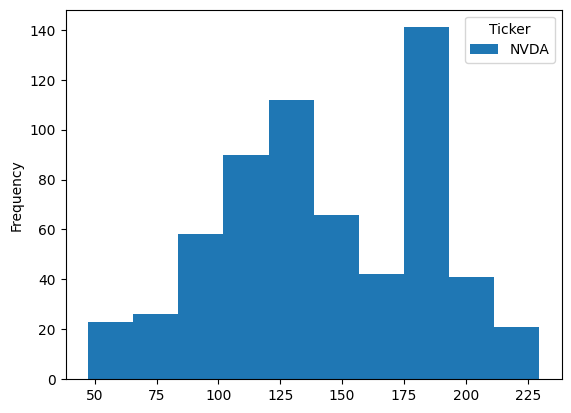

In [14]:
NVDA_data['Open'].plot(kind='hist')

<Axes: xlabel='Date'>

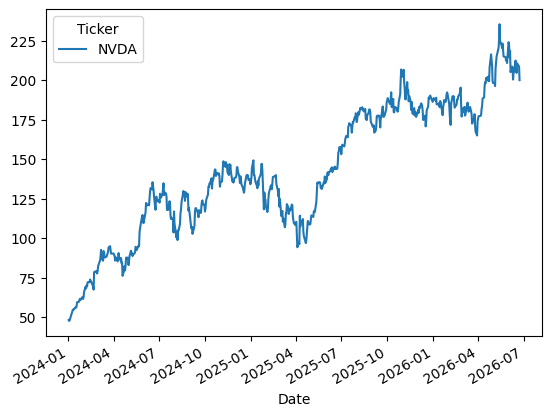

In [15]:
NVDA_data['Close'].plot()

<Axes: title={'center': 'Frequency Plot NVDA'}, xlabel='price', ylabel='Frequency'>

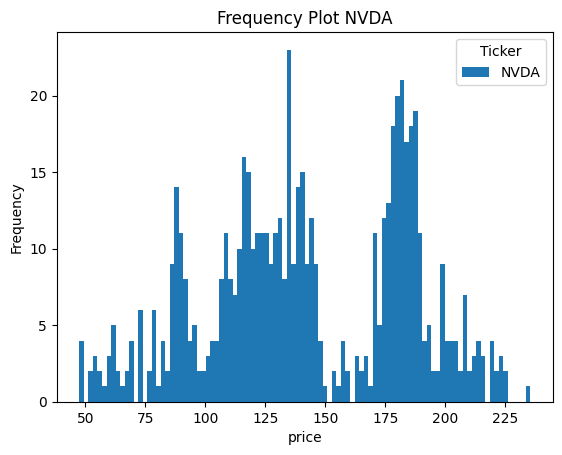

In [16]:
NVDA_data['Close'].plot(
    kind='hist',
    bins=100,
    xlabel='price',
    title="Frequency Plot NVDA"
)

## Boxplot

In [17]:
close_data_all = stock_data['Close']

<Axes: xlabel='Date'>

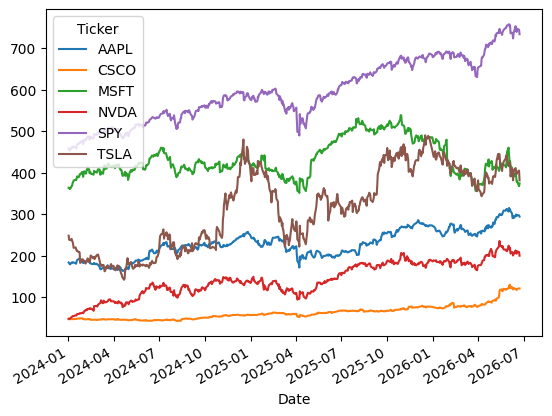

In [18]:
close_data_all.plot()

<Axes: >

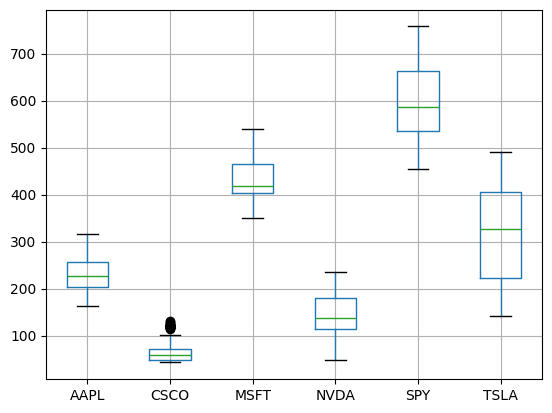

In [19]:
close_data_all.boxplot()

In [20]:
# data = stock_data.describe()
# ticker_name = 'NVDA'
def get_max_limit_IQR(data, ticker_name):
    first_quart = data['Close'][ticker_name]['25%']
    third_quart = data['Close'][ticker_name]['75%']
    IQR = third_quart - first_quart

    max_limit = third_quart + 1.5 * IQR
    #max_limit = None
    return max_limit

In [21]:
get_max_limit_IQR(stock_data.describe(), 'NVDA')

np.float64(280.7829418182373)

## Correlation

In [22]:
msft_spy_corr = close_data_all['MSFT'].corr(close_data_all['SPY'])
print(f"Correlation between MSFT and SPY is: {round(msft_spy_corr, 3)}")

Correlation between MSFT and SPY is: 0.414


In [29]:
close_data_all['MSFT'].head()

,MSFT
Date,
2024-01-02,363.801453
2024-01-03,363.536621
2024-01-04,360.927338
2024-01-05,360.740967
2024-01-08,367.548706


In [30]:
close_data_all['SPY'].head()

,SPY
Date,
2024-01-02,458.809174
2024-01-03,455.062256
2024-01-04,453.596436
2024-01-05,454.217712
2024-01-08,460.702118


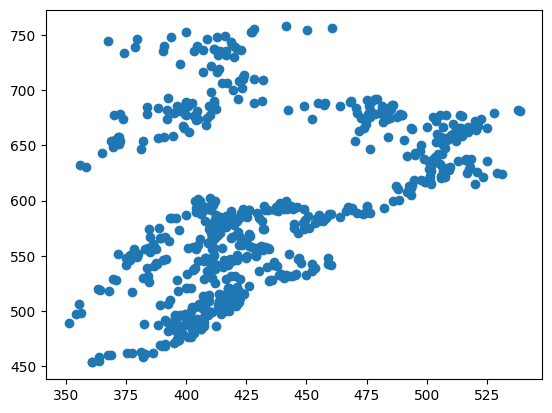

In [23]:
plt.scatter(close_data_all['MSFT'], close_data_all['SPY'])

### Parametric

### Non-parametric

In [24]:
msft_spy_corr_spearman = close_data_all['MSFT'].corr(close_data_all['SPY'], method='spearman')
print(f"Spearman correlation between MSFT and SPY is: {round(msft_spy_corr_spearman, 3)}")

Spearman correlation between MSFT and SPY is: 0.415


### Heatmap

In [25]:
close_data_all.corr()

Ticker,AAPL,CSCO,MSFT,NVDA,SPY,TSLA
Ticker,,,,,,
AAPL,1.000000,0.824307,0.236356,0.866827,0.907176,0.834909
CSCO,0.824307,1.000000,0.164582,0.836899,0.903993,0.727797
MSFT,0.236356,0.164582,1.000000,0.500297,0.413880,0.456974
NVDA,0.866827,0.836899,0.500297,1.000000,0.974607,0.831477
SPY,0.907176,0.903993,0.413880,0.974607,1.000000,0.873625
TSLA,0.834909,0.727797,0.456974,0.831477,0.873625,1.000000


<Axes: xlabel='Ticker', ylabel='Ticker'>

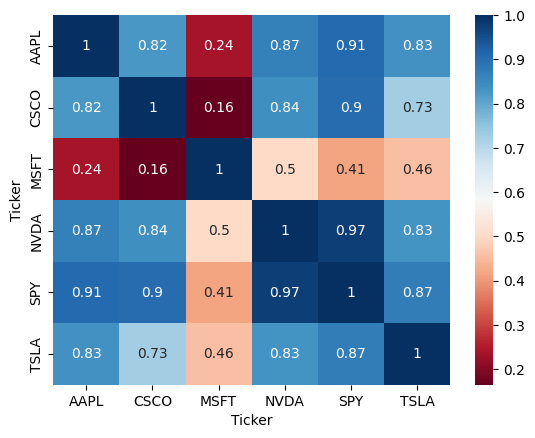

In [26]:
sns.heatmap(
    close_data_all.corr(),
    annot=True,
    cmap='RdBu'
)

## Autocorrelation

In [27]:
# The autocorrelation and plot is essentially just a scatter plot for a sequence of values where
# The X coord is value at time T (in this case 2024-01-02) and T+1 (2024-01-03)
close_data_all['NVDA'].head()

,NVDA
Date,
2024-01-02,48.082535
2024-01-03,47.484600
2024-01-04,47.912838
2024-01-05,49.009884
2024-01-08,52.160286


## Careful with autocorrelation

In [31]:
# Lets line up these points in a table to create a scatter plot

close_data_nvda_df = {
    'close_time_t': list(close_data_all['NVDA'])[0:-1],
    'close_time_t_plus_1': list(close_data_all['NVDA'])[1:]
}

close_data_nvda_df = pd.DataFrame(close_data_nvda_df)
close_data_nvda_df.head()

## For fun: Can you modify the code above to be a lag of n with a lag = n variable

,close_time_t,close_time_t_plus_1
0,48.082535,47.484600
1,47.484600,47.912838
2,47.912838,49.009884
3,49.009884,52.160286
4,52.160286,53.045715


                     close_time_t  close_time_t_plus_1
close_time_t             1.000000             0.995217
close_time_t_plus_1      0.995217             1.000000


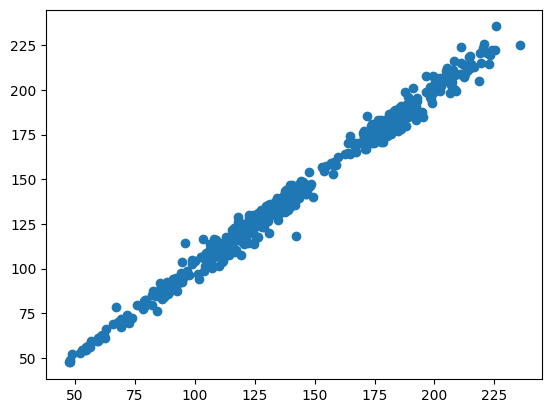

In [32]:
### Now lets just plot a scatter plot and get the correlation - notice this plot
### And the first one below are exactly the same
plt.scatter(
    x= 'close_time_t',
    y= 'close_time_t_plus_1',
    data=close_data_nvda_df)
print(close_data_nvda_df.corr())

<Axes: title={'center': '100 day lag'}, xlabel='y(t)', ylabel='y(t + 100)'>

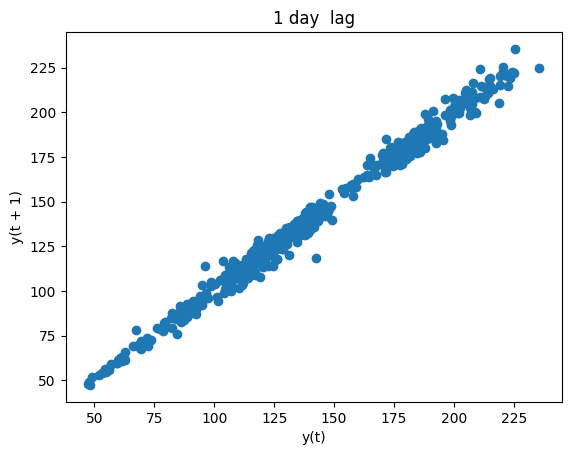

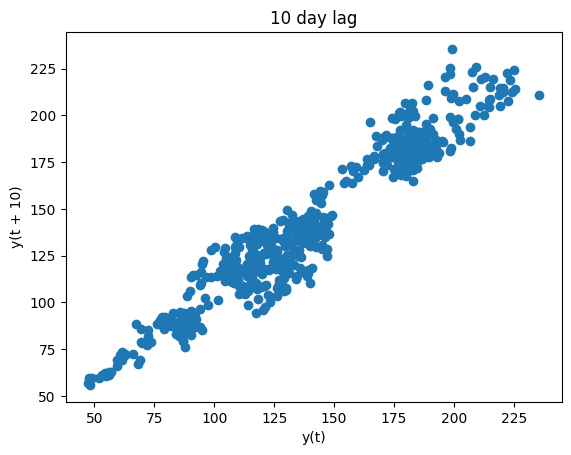

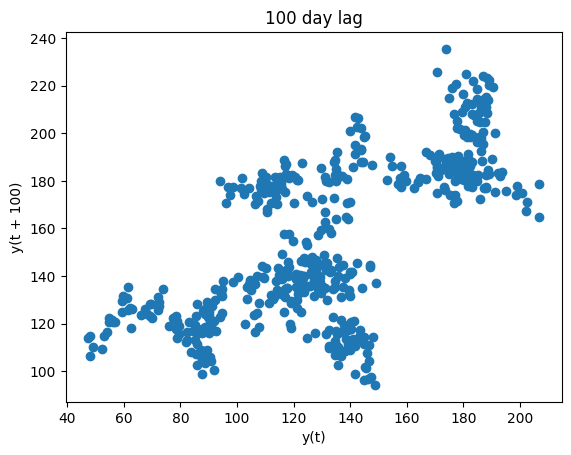

In [36]:
lag_plot(close_data_all['NVDA'])
plt.title("1 day  lag")
plt.figure()
plt.title("10 day lag")
lag_plot(close_data_all['NVDA'], lag = 10)
plt.figure()
plt.title("100 day lag")
lag_plot(close_data_all['NVDA'], lag = 100)

<Axes: xlabel='Lag', ylabel='Autocorrelation'>

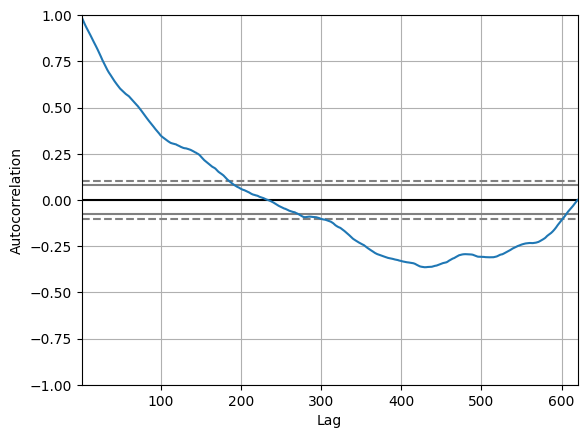

In [38]:
pd.plotting.autocorrelation_plot(close_data_all['NVDA'].dropna())
#pd.plotting.autocorrelation_plot(close_data_all['NVDA'].diff().dropna())

In [39]:
NVDA_data = stock_data.loc[:, (slice(None), 'NVDA')]

<Axes: xlabel='close_NVDA', ylabel='lag_volume_NVDA'>

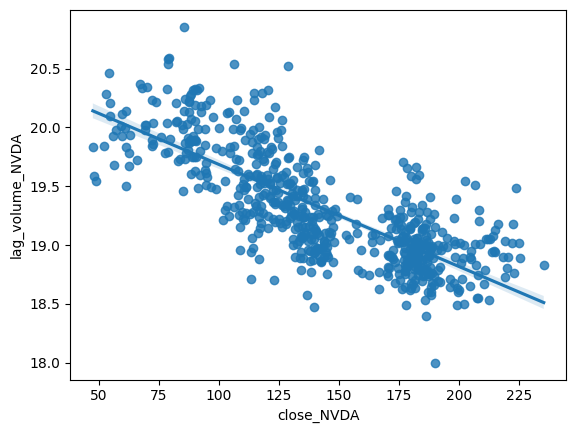

In [40]:
close_NVDA = NVDA_data['Close'][1:].values.reshape(1, -1)[0]
lag_volume_NVDA = np.log(NVDA_data['Volume'][0:-1].values.reshape(1, -1)[0])

data_for_df = {
    'close_NVDA': close_NVDA,
    'lag_volume_NVDA': lag_volume_NVDA
}

NVDA_lag_data = pd.DataFrame(data_for_df)
sns.regplot(
    x= 'close_NVDA',
    y= 'lag_volume_NVDA',
    data=NVDA_lag_data)

<Axes: xlabel='diff_NVDA', ylabel='lag_volume_NVDA'>

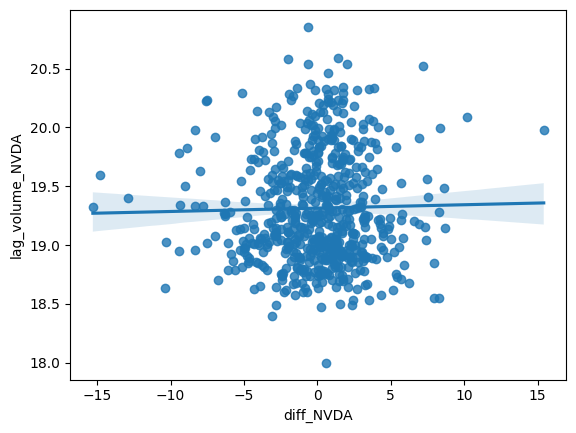

In [41]:
diff_NVDA = NVDA_data['Close'][1:].values.reshape(1, -1)[0] - NVDA_data['Open'][1:].values.reshape(1, -1)[0]
data_for_df['diff_NVDA'] = diff_NVDA

diff_data = pd.DataFrame(data_for_df)
sns.regplot(
    x= 'diff_NVDA',
    y= 'lag_volume_NVDA',
    data=diff_data)

## Probability

<Axes: ylabel='Frequency'>

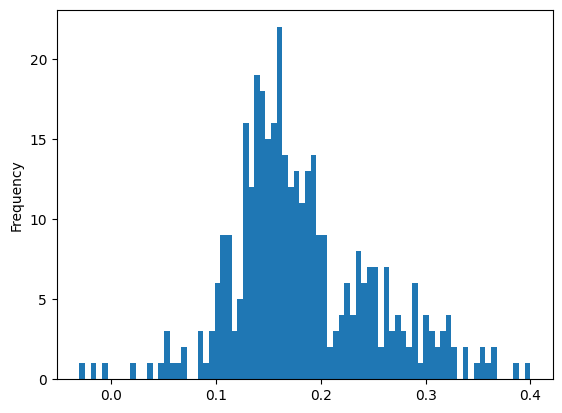

In [52]:
close_data_all['SPY'].pct_change(252).dropna().plot(kind='hist', bins=80)

In [75]:
value = 0.2
p_greater = 1 - norm.cdf(value,
                         close_data_all['NVDA'].pct_change(252).dropna().mean(),
                         close_data_all['NVDA'].pct_change(252).dropna().std())

In [76]:
print(f"Probability of return greater than {value} is: {round(p_greater,4)}")

Probability of return greater than 0.2 is: 0.8411
